## 0. Preparação do ambiente
Importe as bibliotecas principais e configure opções de visualização.

In [ ]:
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_rows', 10)
pd.set_option('display.width', 120)
print('Versões:', {'pandas': pd.__version__, 'numpy': np.__version__})


Versões: {'pandas': '2.2.3', 'numpy': '2.1.3'}


## 1) Leitura e Escrita


Aqui, usamos um **DataFrame exemplo** apenas para demonstrar as operações de E/S.

In [ ]:
# Diretório de trabalho (equivalente ao getwd do R)
os.getcwd()


'/content'

In [ ]:
# Criamos um DataFrame exemplo (substitui o 'Titanic' do R)
df_exemplo = pd.DataFrame({
    'classe': ['1st', '2nd', '3rd', 'Crew'],
    'sobreviventes': [200, 119, 181, 212],
    'total': [325, 285, 706, 885]
})
df_exemplo.head()


,classe,sobreviventes,total
0,1st,200,325
1,2nd,119,285
2,3rd,181,706
3,Crew,212,885


In [ ]:
# Escrever como texto separado por tab (equivalente a write.table no R)
df_exemplo.to_csv('teste.txt', sep='\t', index=False)

# Ler de volta
x = pd.read_csv('teste.txt', sep='\t')
x.head()


,classe,sobreviventes,total
0,1st,200,325
1,2nd,119,285
2,3rd,181,706
3,Crew,212,885


In [ ]:
# Exemplo com Titanic (dataset builtin do seaborn)
import seaborn as sns
titanic = sns.load_dataset("titanic")
titanic.to_csv("teste.txt", sep="\t", index=False)
x = pd.read_csv("teste.txt", sep="\t")
print(x.head())


   survived  pclass     sex   age  sibsp  parch     fare embarked  class    who  adult_male deck  embark_town alive  \
0         0       3    male  22.0      1      0   7.2500        S  Third    man        True  NaN  Southampton    no   
1         1       1  female  38.0      1      0  71.2833        C  First  woman       False    C    Cherbourg   yes   
2         1       3  female  26.0      0      0   7.9250        S  Third  woman       False  NaN  Southampton   yes   
3         1       1  female  35.0      1      0  53.1000        S  First  woman       False    C  Southampton   yes   
4         0       3    male  35.0      0      0   8.0500        S  Third    man        True  NaN  Southampton    no   

   alone  
0  False  
1  False  
2   True  
3  False  
4   True  


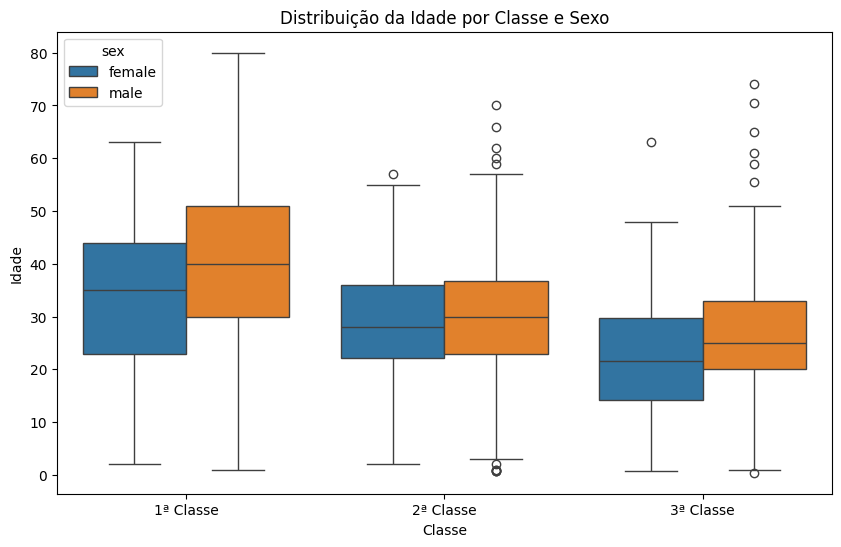

In [ ]:
# Boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(x='pclass', y='age', hue='sex', data=titanic)
plt.xlabel('Classe')
plt.ylabel('Idade')
plt.title('Distribuição da Idade por Classe e Sexo')
plt.xticks(ticks=[0, 1, 2], labels=['1ª Classe', '2ª Classe', '3ª Classe'])
plt.show()

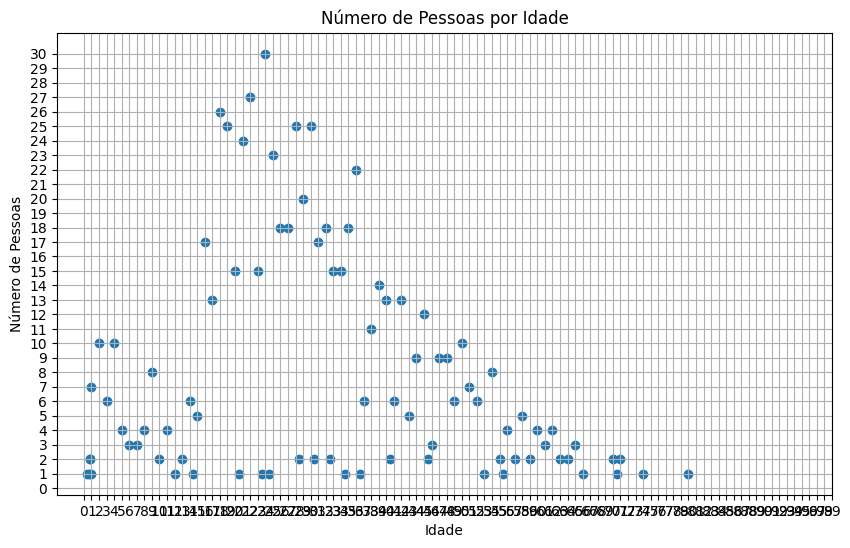

In [ ]:
# Cria o novo dataframe
age_counts = titanic['age'].value_counts().reset_index()
age_counts.columns = ['age', 'count']

# Cria o gráfico
plt.figure(figsize=(10, 6))
plt.scatter(age_counts['age'], age_counts['count'])
plt.xlabel('Idade')
plt.ylabel('Número de Pessoas')
plt.title('Número de Pessoas por Idade')
plt.yticks(ticks=list(range(31)))
plt.xticks(ticks=list(range(100)))
plt.grid(True)
plt.show()

/tmp/ipykernel_1427/354362314.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = titanic.groupby(['sex', 'pclass', 'age_group', 'survived']).size().unstack(fill_value=0)


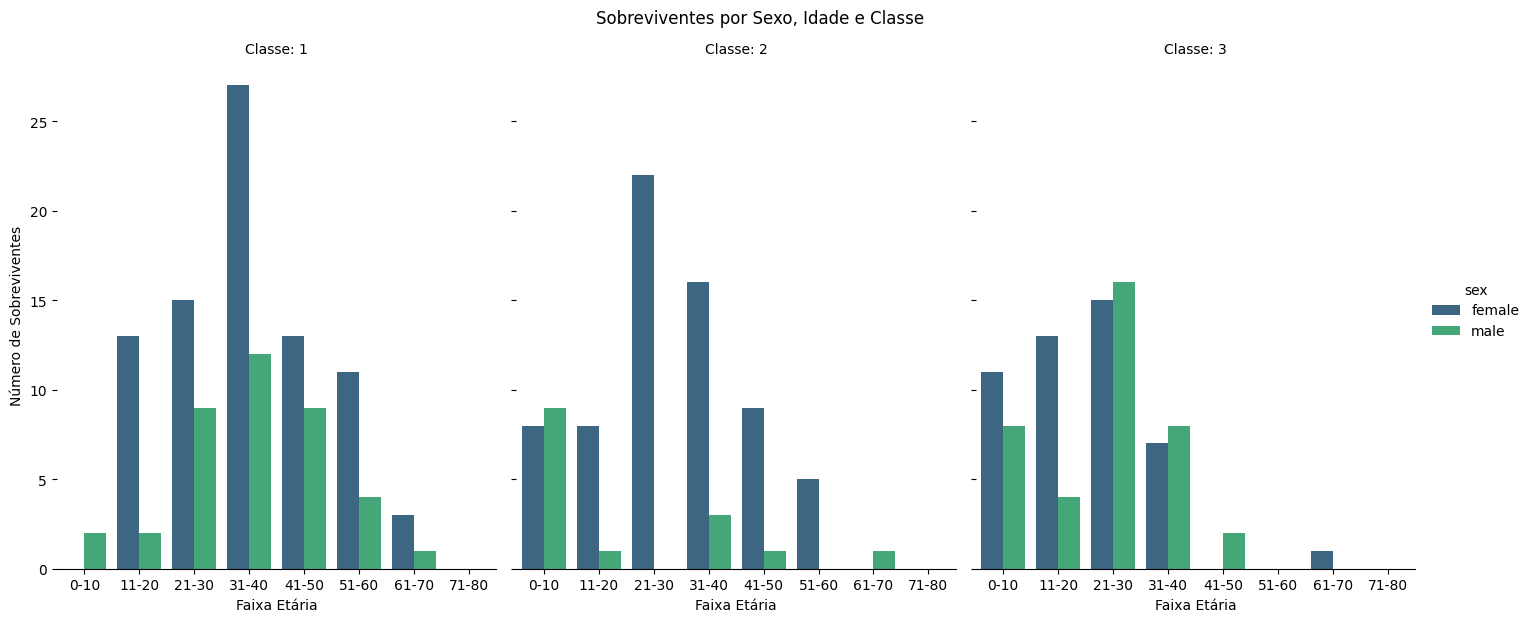

In [ ]:
# Cria os bins de idade
bins = [0, 10, 20, 30, 40, 50, 60, 70, 80]
labels = ['0-10', '11-20', '21-30', '31-40', '41-50', '51-60', '61-70', '71-80']
titanic['age_group'] = pd.cut(titanic['age'], bins=bins, labels=labels, right=False)

# Agrupamento por sex, pclass, age_group e survived
grouped = titanic.groupby(['sex', 'pclass', 'age_group', 'survived']).size().unstack(fill_value=0)

# Seleciona apenas os sobreviventes
survivors = grouped[1]

# Reseta o índice e renomeia a coluna de sobreviventes
survivors = survivors.reset_index()
survivors = survivors.rename(columns={1: 'survived_count'})

# Criando o gráfico
import matplotlib.pyplot as plt
import seaborn as sns

g = sns.catplot(x="age_group", y="survived_count",
                hue="sex", col="pclass",
                data=survivors, kind="bar", palette="viridis", height=6, aspect=.8)

g.fig.suptitle('Sobreviventes por Sexo, Idade e Classe', y=1.03)
g.set_axis_labels("Faixa Etária", "Número de Sobreviventes")
g.set_titles("Classe: {col_name}")
g.despine(left=True) #ajusta as bordar do gráfico
plt.show()

## 2) Tratamentos de Dados (Cepagri)



In [ ]:
# Mount Google Drive
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

# Colunas e leitura do CSV do Cepagri (equivalente ao read.table/read.csv com sep=';')
names = ['horario', 'temp', 'vento', 'umid', 'sensa']
# Use the local path from Google Drive
file_path = '/content/drive/MyDrive/2025.2/IA/Tutoriais/cepagri.csv'

# Para trazer tudo como string inicialmente, usamos dtype=str
cepagri = pd.read_csv(file_path, header=None, sep=';', names=names, dtype=str)

#linhas específicas e tail
display(cepagri.iloc[26490:26492])
cepagri.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,horario,temp,vento,umid,sensa
26490,12/09/2014-17:50,[ERRO],NaN,NaN,NaN
26491,12/09/2014-18:00,32.6,30.0,19.2,26.0


,horario,temp,vento,umid,sensa
0,02/03/2014-19:08,23.7,59.3,77.1,22.6
1,02/03/2014-19:18,23.4,59.1,77.9,22.3
2,02/03/2014-19:28,23.2,56.7,78.9,22.1
3,02/03/2014-19:38,23.0,55.4,79.2,21.9
4,02/03/2014-19:48,22.8,52.6,79.7,21.7


In [ ]:
COND = cepagri['temp'] != ' [ERRO]'
cepagri[COND]
cepagri[cepagri['temp'] != ' [ERRO]']
cepagri[~cepagri['temp'].str.upper().str.contains('[ERRO]')]


,horario,temp,vento,umid,sensa
0,02/03/2014-19:08,23.7,59.3,77.1,22.6
1,02/03/2014-19:18,23.4,59.1,77.9,22.3
2,02/03/2014-19:28,23.2,56.7,78.9,22.1
3,02/03/2014-19:38,23.0,55.4,79.2,21.9
4,02/03/2014-19:48,22.8,52.6,79.7,21.7
...,...,...,...,...,...
590862,17/08/2025-21:50,19.6,18.6,77.4,NaN
590863,17/08/2025-22:00,19.5,16.9,77.3,NaN
590864,17/08/2025-22:10,19.4,16.6,77.8,NaN
590865,17/08/2025-22:20,19.2,17.9,78.4,NaN


In [ ]:
# Remoção de linhas com temp == ' [ERRO]'
l1 = len(cepagri)
cepagri = cepagri[cepagri['temp'] != ' [ERRO]']
l2 = len(cepagri)
print('Removidos:', l1 - l2)
print('Proporção removida:', (l1 - l2) / l1 if l1 else float('nan'))

# Conversões de tipo
cepagri['temp']  = pd.to_numeric(cepagri['temp'], errors='coerce')
cepagri['vento'] = pd.to_numeric(cepagri['vento'], errors='coerce')
cepagri['umid']  = pd.to_numeric(cepagri['umid'], errors='coerce')
cepagri['sensa'] = pd.to_numeric(cepagri['sensa'], errors='coerce')

cepagri['horario'] = pd.to_datetime(
    cepagri['horario'], format='%d/%m/%Y-%H:%M', errors='coerce'
)

# Se desejar, associe o fuso explicitamente
try:
    cepagri['horario'] = cepagri['horario'].dt.tz_localize('America/Sao_Paulo', nonexistent='NaT', ambiguous='NaT')
except Exception as e:
    print('Aviso de fuso horário:', e)

# Resumos (equivalente a summary no R)
display(cepagri['temp'].describe())
display(cepagri['horario'].describe())
display(cepagri['sensa'].describe())


Removidos: 47147
Proporção removida: 0.07979291447990834


,temp
count,543720.000000
mean,21.886687
std,33.004912
min,-7999.000000
25%,18.600000
50%,21.500000
75%,25.600000
max,38.100000


,horario
count,543678
mean,2019-09-24 02:44:48.856564992-03:00
min,2014-03-02 19:08:00-03:00
25%,2016-10-27 12:12:30-02:00
50%,2019-06-16 20:05:00-03:00
75%,2022-09-21 02:07:30-03:00
max,2025-08-17 22:30:00-03:00


,sensa
count,443824.000000
mean,19.860886
std,5.937877
min,-8.200000
25%,16.600000
50%,19.900000
75%,23.900000
max,99.900000


In [ ]:
# display(cepagri.head())
# print(cepagri.dtypes)
cepagri[~cepagri['sensa'].isna()]

,horario,temp,vento,umid,sensa
0,2014-03-02 19:08:00-03:00,23.7,59.3,77.1,22.6
1,2014-03-02 19:18:00-03:00,23.4,59.1,77.9,22.3
2,2014-03-02 19:28:00-03:00,23.2,56.7,78.9,22.1
3,2014-03-02 19:38:00-03:00,23.0,55.4,79.2,21.9
4,2014-03-02 19:48:00-03:00,22.8,52.6,79.7,21.7
...,...,...,...,...,...
481401,2023-06-14 16:20:00-03:00,17.8,0.5,22.1,16.1
481402,2023-06-14 16:30:00-03:00,17.8,4.6,22.1,16.1
481403,2023-06-14 16:40:00-03:00,17.8,2.7,22.1,16.1
481404,2023-06-14 16:50:00-03:00,17.7,1.6,22.2,16.0


In [ ]:
# Verificações específicas (equivalente aos filtros mostrados no R)
neg_sensa = cepagri.loc[cepagri['sensa'].notna() & (cepagri['sensa'] < 0)]
eq_999   = cepagri.loc[cepagri['sensa'].notna() & (cepagri['sensa'] == 99.9)]

display(neg_sensa.head(10))
display(neg_sensa.tail(10))
display(eq_999.head(10))
display(eq_999.tail(10))

# Substituir 99.9 por NA (NaN) como no R
cepagri.loc[cepagri['sensa'] == 99.9, 'sensa'] = np.nan
cepagri['sensa'].describe()


,horario,temp,vento,umid,sensa
14716,2014-06-19 21:50:00-03:00,14.0,68.4,85.2,-0.2
14717,2014-06-19 22:00:00-03:00,14.0,67.8,85.2,-0.1
18946,2014-07-20 23:40:00-03:00,12.6,60.6,83.2,-0.3
18948,2014-07-21 00:00:00-03:00,12.5,62.4,83.4,-0.8
18949,2014-07-21 00:10:00-03:00,12.4,63.3,83.7,-1.0
18950,2014-07-21 00:20:00-03:00,12.2,63.2,84.0,-1.1
18951,2014-07-21 00:30:00-03:00,12.1,63.1,84.5,-1.3
18952,2014-07-21 00:40:00-03:00,12.0,64.9,84.9,-1.7
18953,2014-07-21 00:50:00-03:00,12.0,61.3,84.9,-1.1
18954,2014-07-21 01:00:00-03:00,11.9,62.1,85.2,-1.3


,horario,temp,vento,umid,sensa
133057,2016-09-30 21:00:00-03:00,16.5,83.1,78.3,-0.2
133060,2016-09-30 21:30:00-03:00,16.3,82.8,78.6,-0.4
133061,2016-09-30 21:40:00-03:00,16.3,82.2,78.7,-0.3
133062,2016-09-30 21:50:00-03:00,16.2,83.3,78.9,-0.6
133063,2016-09-30 22:00:00-03:00,16.2,80.9,79.0,-0.2
133064,2016-09-30 22:10:00-03:00,16.1,82.8,79.1,-0.6
133207,2016-10-01 22:00:00-03:00,16.4,82.1,80.9,-0.1
134353,2016-10-09 21:00:00-03:00,18.0,92.4,75.5,-0.3
134372,2016-10-10 00:10:00-03:00,16.6,83.9,82.9,-0.2
425864,2022-05-20 06:10:00-03:00,4.6,5.3,85.2,-0.2


,horario,temp,vento,umid,sensa
114705,2016-05-26 07:10:00-03:00,13.8,16.9,94.5,99.9
114849,2016-05-27 07:10:00-03:00,14.3,19.7,98.1,99.9
114993,2016-05-28 07:10:00-03:00,16.1,47.1,91.5,99.9
115137,2016-05-29 07:10:00-03:00,14.8,31.3,94.8,99.9
115281,2016-05-30 07:10:00-03:00,14.1,16.2,96.6,99.9
115425,2016-05-31 07:10:00-03:00,15.7,15.5,100.0,99.9
115569,2016-06-01 07:10:00-03:00,15.6,14.3,100.0,99.9
115713,2016-06-02 07:10:00-03:00,16.5,4.8,100.0,99.9
115856,2016-06-03 07:10:00-03:00,16.3,14.2,100.0,99.9
115991,2016-06-04 07:10:00-03:00,17.9,1.4,100.0,99.9


,horario,temp,vento,umid,sensa
134558,2016-10-11 07:10:00-03:00,17.7,38.0,84.3,99.9
134702,2016-10-12 07:10:00-03:00,19.0,17.3,83.5,99.9
134846,2016-10-13 07:10:00-03:00,21.3,17.9,82.6,99.9
134990,2016-10-14 07:10:00-03:00,20.4,9.8,95.3,99.9
135134,2016-10-15 07:10:00-03:00,20.1,25.0,94.5,99.9
233724,2018-09-07 07:10:00-03:00,13.4,37.0,75.3,99.9
233868,2018-09-08 07:10:00-03:00,16.1,26.3,64.5,99.9
234012,2018-09-09 07:10:00-03:00,15.1,28.1,75.8,99.9
234156,2018-09-10 07:10:00-03:00,14.8,33.4,74.5,99.9
234300,2018-09-11 07:10:00-03:00,15.4,34.7,76.2,99.9


,sensa
count,443682.000000
mean,19.835269
std,5.763566
min,-8.200000
25%,16.600000
50%,19.900000
75%,23.900000
max,34.700000


## 3) Valores **consecutivos** (duas abordagens)

### 3.1) Função `consecutive`
Marca como `True` todos os índices pertencentes a **qualquer sequência** de tamanho `k` (ou maior) de **valores idênticos consecutivos**.

In [ ]:
def consecutive(values, k=2):
    """
    Retorna um vetor booleano (numpy array) marcando True onde houver
    sequências de tamanho >= k de valores idênticos consecutivos.
    A marcação abrange todos os elementos da sequência.
    """
    arr = np.asarray(values)
    n = arr.size
    result = np.zeros(n, dtype=bool)
    if n == 0 or k <= 1:
        return np.ones(n, dtype=bool) if k <= 1 else result
    run_len = 1
    for i in range(1, n):
        if arr[i] == arr[i-1]:
            run_len += 1
            if run_len >= k:
                result[i-k+1:i+1] = True
        else:
            run_len = 1
    return result

print('10 iguais, k=10 ->', consecutive(np.repeat(1, 10), 10).sum(), 'marcados (esperado 10)')
print('10 iguais, k=3  ->', consecutive(np.repeat(1, 10), 3).sum(),  'marcados (esperado 10)')


10 iguais, k=10 -> 10 marcados (esperado 10)
10 iguais, k=3  -> 10 marcados (esperado 10)


### 3.2) Apenas **pandas** (sem função auxiliar)

Usamos `shift()` para detectar **mudanças de valor**, `cumsum()` para criar um **ID de sequência** e então calculamos o **tamanho da sequência** por `value_counts()`/`map`.

In [ ]:
df_aux = {'col': [0,1,1,1,3,4,5,5,5,5,5,6,7,8]}
df_aux = pd.DataFrame(df_aux)

mask = df_aux['col'].ne(df_aux['col'].shift())
display(mask.head())
run_id = mask.cumsum()

display(run_id.head(10))

display(run_id.value_counts())
run_len = run_id.map(run_id.value_counts())
run_len.head(10)



,col
0,True
1,True
2,False
3,False
4,True


,col
0,1
1,2
2,2
3,2
4,3
5,4
6,5
7,5
8,5
9,5


,count
col,
5,5
2,3
3,1
1,1
4,1
6,1
7,1
8,1


,col
0,1
1,3
2,3
3,3
4,1
5,1
6,5
7,5
8,5
9,5


In [ ]:
# Detectar sequências consecutivas em uma coluna, por exemplo 'temp'
col = 'temp'
mask_change = cepagri[col].ne(cepagri[col].shift())  # True quando o valor muda
run_id = mask_change.cumsum()                        # ID incremental de run
run_len = run_id.map(run_id.value_counts())          # tamanho da run de cada linha

# Ex.: linhas que pertencem a sequências de tamanho >= 6
k = 6
filtro_ge_k = run_len.ge(k)

print('Total de linhas com sequências >= 6 em \"temp\":', int(filtro_ge_k.sum()))
cepagri.loc[filtro_ge_k].head()


Total de linhas com sequências >= 6 em "temp": 46472


,horario,temp,vento,umid,sensa
456,2014-03-05 23:10:00-03:00,20.7,18.1,98.5,19.6
457,2014-03-05 23:20:00-03:00,20.7,19.5,98.9,19.6
458,2014-03-05 23:30:00-03:00,20.7,20.3,99.0,19.5
459,2014-03-05 23:40:00-03:00,20.7,18.5,99.0,19.6
460,2014-03-05 23:50:00-03:00,20.7,18.2,99.0,19.5


In [ ]:
# Extensão: aplicar a várias colunas (temp, vento, umid) e exigir que TODAS tenham sequência >= k
def run_len_col(s: pd.Series) -> pd.Series:
    mask_change = s.ne(s.shift())
    run_id = mask_change.cumsum()
    return run_id.map(run_id.value_counts())

k = 6
rl_temp = run_len_col(cepagri['temp'])
rl_vento = run_len_col(cepagri['vento'])
rl_umid = run_len_col(cepagri['umid'])

filtro_all = rl_temp.ge(k) & rl_vento.ge(k) & rl_umid.ge(k)
int(filtro_all.sum())


18574

In [ ]:
# Checagens de janelas longas (aproximações de 1 a 15 dias)
# Observação: isso supõe que as leituras sejam em intervalos regulares.
for k in [144, 288, 720, 1440, 2160, 1584]:
    any_k = run_len_col(cepagri['temp']).ge(k).any()
    print(f'Existe sequência de temp com pelo menos {k} leituras? -> {bool(any_k)}')


Existe sequência de temp com pelo menos 144 leituras? -> True
Existe sequência de temp com pelo menos 288 leituras? -> True
Existe sequência de temp com pelo menos 720 leituras? -> True
Existe sequência de temp com pelo menos 1440 leituras? -> True
Existe sequência de temp com pelo menos 2160 leituras? -> False
Existe sequência de temp com pelo menos 1584 leituras? -> False


In [ ]:
# Dias (datas) em que houve sequência de 'temp' com pelo menos 144 leituras
k = 144
filtro = run_len_col(cepagri['temp']).ge(k)
datas_unicas = pd.to_datetime(cepagri.loc[filtro, 'horario']).dt.date.unique()
datas_unicas


array([datetime.date(2014, 9, 12), datetime.date(2014, 9, 13),
       datetime.date(2014, 9, 14), datetime.date(2015, 6, 20),
       datetime.date(2015, 6, 21), datetime.date(2015, 6, 22),
       datetime.date(2016, 7, 30), datetime.date(2016, 7, 31),
       datetime.date(2017, 4, 28), datetime.date(2017, 4, 29),
       datetime.date(2017, 4, 30), datetime.date(2017, 5, 3),
       datetime.date(2017, 5, 4), datetime.date(2017, 5, 5),
       datetime.date(2018, 10, 12), datetime.date(2018, 10, 13),
       datetime.date(2018, 10, 14), datetime.date(2018, 10, 15),
       datetime.date(2018, 10, 16), datetime.date(2018, 10, 17),
       datetime.date(2018, 10, 18), datetime.date(2018, 10, 19),
       datetime.date(2018, 10, 20), datetime.date(2018, 10, 21),
       datetime.date(2018, 10, 22), datetime.date(2018, 10, 23),
       datetime.date(2018, 10, 24), datetime.date(2018, 10, 25),
       datetime.date(2018, 10, 26), datetime.date(2018, 10, 27),
       datetime.date(2018, 10, 28), dateti

## 4) Exemplo de Análise de Dados

Repetimos o fluxo de limpeza + conversões, criamos colunas de **ano** e **mês**, e calculamos médias.
Também comparamos **2017** e **2018** em termos de:
- fração de leituras em sequências de tamanho ≥ 6;
- número de valores distintos por mês;
- gráficos (boxplot, violino e dispersão) com **matplotlib**.

In [ ]:
# Releitura para garantir pipeline isolado (pode pular se já executou antes)
names = ['horario', 'temp', 'vento', 'umid', 'sensa']
cepagri = pd.read_csv(file_path, header=None, sep=';', names=names, dtype=str)
cepagri = cepagri[cepagri['temp'] != ' [ERRO]'].copy()

cepagri['temp']  = pd.to_numeric(cepagri['temp'], errors='coerce')
cepagri['vento'] = pd.to_numeric(cepagri['vento'], errors='coerce')
cepagri['umid']  = pd.to_numeric(cepagri['umid'], errors='coerce')
cepagri['sensa'] = pd.to_numeric(cepagri['sensa'], errors='coerce')

cepagri['horario'] = pd.to_datetime(cepagri['horario'], format='%d/%m/%Y-%H:%M', errors='coerce')
cepagri['ano'] = cepagri['horario'].dt.year
cepagri['mes'] = cepagri['horario'].dt.month

#
display(cepagri.groupby('ano')['temp'].mean())
display(cepagri.groupby('mes')['temp'].mean())
display(cepagri.groupby('mes')['umid'].mean())

display(cepagri.pivot_table(values='temp', index='ano', columns='mes', aggfunc='mean'))


,temp
ano,
2014,21.735300
2015,21.910884
2016,21.441571
2017,21.655457
2018,22.420304
...,...
2021,22.328319
2022,21.279585
2023,22.273119


,temp
mes,
1,24.021228
2,23.989336
3,22.379331
4,22.269060
5,19.904446
...,...
8,19.704134
9,22.275829
10,23.326547


,umid
mes,
1,70.654792
2,75.170530
3,73.042936
4,69.854533
5,67.669515
...,...
8,60.145850
9,60.143077
10,61.265137


mes,1,2,3,4,5,6,7,8,9,10,11,12
ano,,,,,,,,,,,,
2014,NaN,NaN,23.787194,21.957083,19.528554,19.541228,18.818231,20.092900,22.667040,23.858772,23.193943,23.643411
2015,25.516568,23.508253,22.289647,21.897684,19.118221,18.466985,18.523243,20.603091,22.148963,24.011305,23.448633,23.709705
2016,23.660704,24.670100,23.444183,23.909144,18.900628,16.730232,18.441183,19.590004,20.675307,22.020633,22.042041,23.594841
2017,23.536810,24.844240,22.659107,21.738173,20.168300,18.461476,17.523532,19.333423,23.027130,22.904781,22.399674,23.669194
2018,23.315249,23.277933,24.693052,22.472910,20.275891,20.116983,19.524401,18.740157,21.363802,24.975567,24.619954,25.651514
...,...,...,...,...,...,...,...,...,...,...,...,...
2021,24.452838,23.416606,23.969614,21.007619,19.531164,19.078031,19.510294,20.872764,24.172215,21.187760,22.841050,23.088613
2022,23.506000,24.096375,24.590212,22.498950,18.376277,18.390419,20.172609,18.969582,19.222010,22.333641,21.178273,22.406262
2023,22.779352,23.194987,23.723059,21.097389,19.575365,18.672868,18.706101,20.373609,23.480613,23.349181,24.436630,25.282207


In [ ]:
# Subconjuntos 2017 e 2018
cepagri2017 = cepagri.loc[cepagri['ano'] == 2017].copy()
cepagri2018 = cepagri.loc[cepagri['ano'] == 2018].copy()

def run_len_col(s: pd.Series) -> pd.Series:
    mask_change = s.ne(s.shift())
    run_id = mask_change.cumsum()
    return run_id.map(run_id.value_counts())

def frac_runs_ge_k(series: pd.Series, k: int = 6) -> float:
    """Fração de leituras que pertencem a sequências de tamanho >= k."""
    rl = run_len_col(series)
    m = rl.ge(k)
    return float(m.mean())

print('2017 - fração \"temp\" em sequências >= 6 por mês')
display(cepagri2017.groupby('mes')['temp'].apply(lambda s: frac_runs_ge_k(s, 6)))

print('2018 - fração \"temp\" em sequências >= 6 por mês')
display(cepagri2018.groupby('mes')['temp'].apply(lambda s: frac_runs_ge_k(s, 6)))

print('2017 - nº de valores distintos de \"temp\" por mês')
display(cepagri2017.groupby('mes')['temp'].nunique())

print('2018 - nº de valores distintos de \"temp\" por mês')
display(cepagri2018.groupby('mes')['temp'].nunique())


2017 - fração "temp" em sequências >= 6 por mês


,temp
mes,
1,0.039109
2,0.034757
3,0.046186
4,0.091827
5,0.081750
...,...
8,0.024675
9,0.013194
10,0.030965


2018 - fração "temp" em sequências >= 6 por mês


,temp
mes,
1,0.034067
2,0.026409
3,0.015791
4,0.014818
5,0.014116
...,...
8,0.094514
9,0.033365
10,0.673029


2017 - nº de valores distintos de "temp" por mês


,temp
mes,
1,165
2,170
3,179
4,179
5,164
...,...
8,220
9,213
10,210


2018 - nº de valores distintos de "temp" por mês


,temp
mes,
1,167
2,165
3,150
4,177
5,239
...,...
8,217
9,245
10,161


/tmp/ipykernel_1427/2996388061.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data_2017, labels=sorted(cepagri2017['mes'].dropna().unique()))


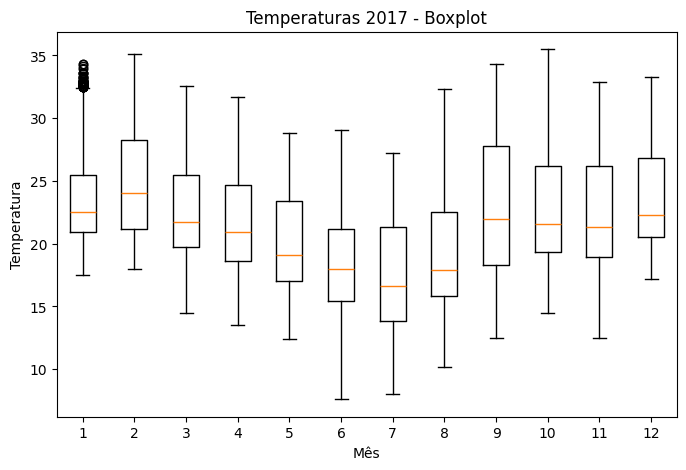

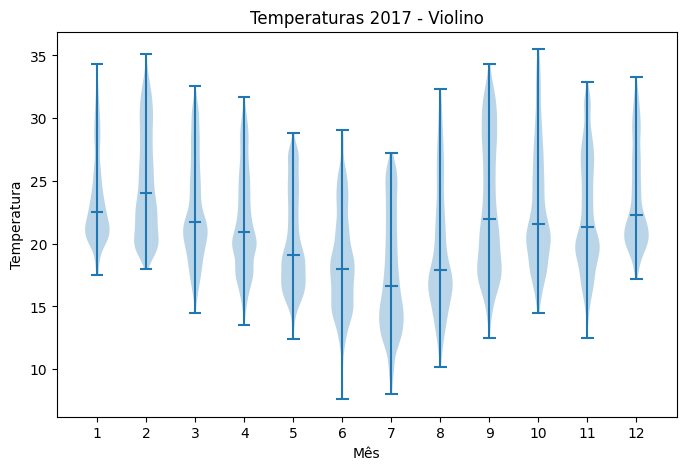

/tmp/ipykernel_1427/2996388061.py:24: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data_2018, labels=sorted(cepagri2018['mes'].dropna().unique()))


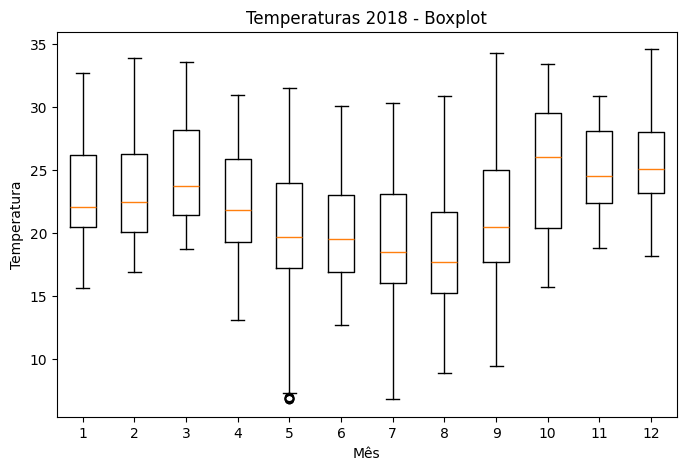

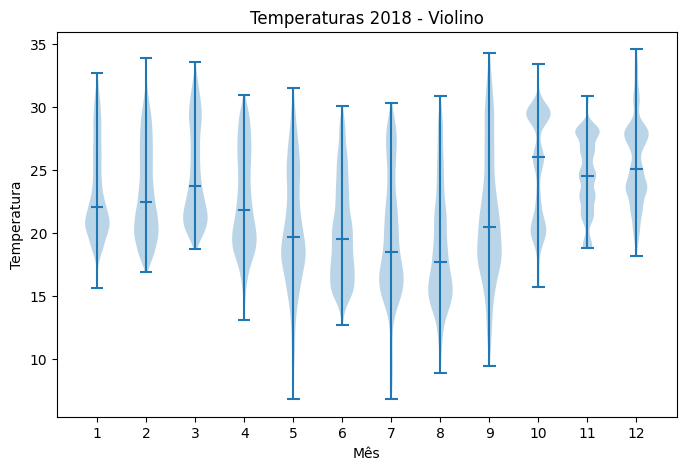

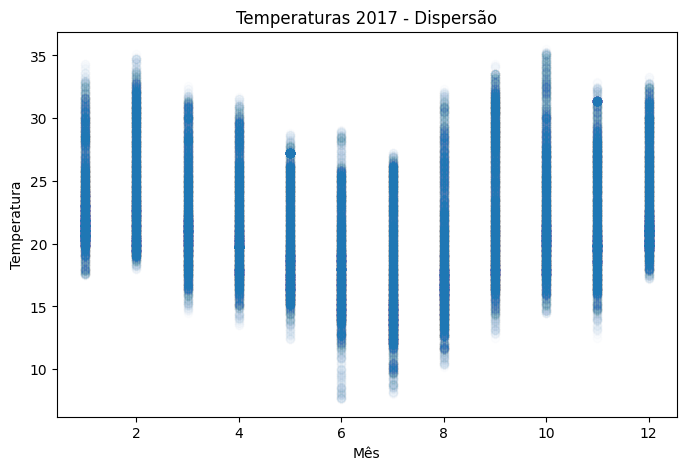

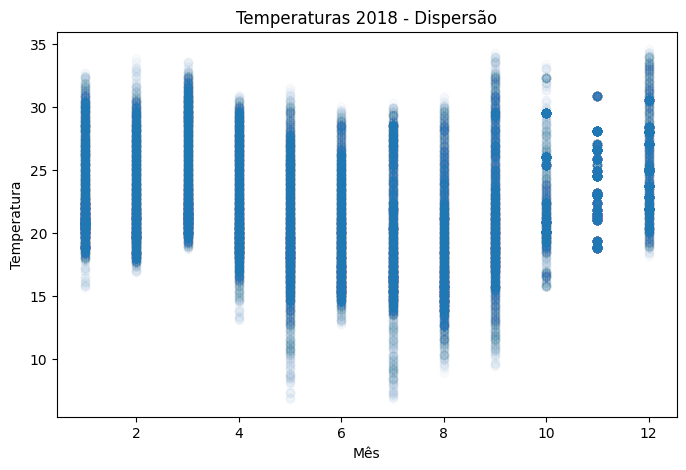

In [ ]:
# --------- Gráficos (matplotlib puro; uma figura por gráfico) ---------

# Boxplot por mês (2017)
plt.figure(figsize=(8, 5))
data_2017 = [cepagri2017.loc[cepagri2017['mes'] == m, 'temp'].dropna().values for m in sorted(cepagri2017['mes'].dropna().unique())]
plt.boxplot(data_2017, labels=sorted(cepagri2017['mes'].dropna().unique()))
plt.xlabel('Mês')
plt.ylabel('Temperatura')
plt.title('Temperaturas 2017 - Boxplot')
plt.show()

# Violin plot por mês (2017)
plt.figure(figsize=(8, 5))
plt.violinplot(data_2017, showmeans=False, showmedians=True)
plt.xticks(ticks=range(1, len(data_2017)+1), labels=sorted(cepagri2017['mes'].dropna().unique()))
plt.xlabel('Mês')
plt.ylabel('Temperatura')
plt.title('Temperaturas 2017 - Violino')
plt.show()

# Boxplot por mês (2018)
plt.figure(figsize=(8, 5))
data_2018 = [cepagri2018.loc[cepagri2018['mes'] == m, 'temp'].dropna().values for m in sorted(cepagri2018['mes'].dropna().unique())]
plt.boxplot(data_2018, labels=sorted(cepagri2018['mes'].dropna().unique()))
plt.xlabel('Mês')
plt.ylabel('Temperatura')
plt.title('Temperaturas 2018 - Boxplot')
plt.show()

# Violin plot por mês (2018)
plt.figure(figsize=(8, 5))
plt.violinplot(data_2018, showmeans=False, showmedians=True)
plt.xticks(ticks=range(1, len(data_2018)+1), labels=sorted(cepagri2018['mes'].dropna().unique()))
plt.xlabel('Mês')
plt.ylabel('Temperatura')
plt.title('Temperaturas 2018 - Violino')
plt.show()

# Dispersão mês vs temp (2017)
plt.figure(figsize=(8, 5))
plt.scatter(cepagri2017['mes'], cepagri2017['temp'], alpha=0.01)
plt.xlabel('Mês')
plt.ylabel('Temperatura')
plt.title('Temperaturas 2017 - Dispersão')
plt.show()

# Dispersão mês vs temp (2018)
plt.figure(figsize=(8, 5))
plt.scatter(cepagri2018['mes'], cepagri2018['temp'], alpha=0.01)
plt.xlabel('Mês')
plt.ylabel('Temperatura')
plt.title('Temperaturas 2018 - Dispersão')
plt.show()
